In [3]:
!pip -q install -U kaggle

In [4]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle authentication token loaded.")

Kaggle authentication token loaded.


In [5]:
!kaggle --version

Kaggle CLI 2.2.5


In [6]:
from pathlib import Path

PROJECT_DIR = Path("/content/Lung_Colon_Cancer_Project")

DATA_DIR = PROJECT_DIR / "dataset"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [DATA_DIR, MODEL_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Cloud project folders created.")

Cloud project folders created.


In [7]:
!kaggle datasets download \
    -d andrewmvd/lung-and-colon-cancer-histopathological-images \
    -p /content/Lung_Colon_Cancer_Project/dataset \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images
License(s): CC-BY-SA-4.0
100% 1.76G/1.76G [00:47<00:00, 39.6MB/s]



In [8]:
import os

for root, dirs, files in os.walk(DATA_DIR):

    if files:
        print(
            "Folder:", root,
            "| Image files:", len([
                f for f in files
                if f.lower().endswith(('.jpg', '.jpeg', '.png'))
            ])
        )

Folder: /content/Lung_Colon_Cancer_Project/dataset/lung_colon_image_set/lung_image_sets/lung_aca | Image files: 5000
Folder: /content/Lung_Colon_Cancer_Project/dataset/lung_colon_image_set/lung_image_sets/lung_n | Image files: 5000
Folder: /content/Lung_Colon_Cancer_Project/dataset/lung_colon_image_set/lung_image_sets/lung_scc | Image files: 5000
Folder: /content/Lung_Colon_Cancer_Project/dataset/lung_colon_image_set/colon_image_sets/colon_aca | Image files: 5000
Folder: /content/Lung_Colon_Cancer_Project/dataset/lung_colon_image_set/colon_image_sets/colon_n | Image files: 5000


In [10]:
from pathlib import Path
DATA_DIR = Path("/content/Lung_Colon_Cancer_Project/dataset")
class_names = [
    "colon_aca",
    "colon_n",
    "lung_aca",
    "lung_n",
    "lung_scc"
]
image_extensions = {".jpg", ".jpeg", ".png"}
class_image_paths = {}
for class_name in class_names:
    matches = list(DATA_DIR.rglob(class_name))
    if not matches:
        raise FileNotFoundError(f"Folder not found: {class_name}")
    class_folder = matches[0]
    images = [
        p for p in class_folder.iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]
    class_image_paths[class_name] = images
    print(f"{class_name}: {len(images)} images")
total_images = sum(len(paths) for paths in class_image_paths.values())
print("\nTotal images:", total_images)

colon_aca: 5000 images
colon_n: 5000 images
lung_aca: 5000 images
lung_n: 5000 images
lung_scc: 5000 images

Total images: 25000


In [11]:
import pandas as pd
records = []
for class_name, paths in class_image_paths.items():
    for path in paths:
        records.append({
            "filepath": str(path),
            "label": class_name
        })

dataset_df = pd.DataFrame(records)
print("Dataset shape:", dataset_df.shape)
display(dataset_df.head())

Dataset shape: (25000, 2)


,filepath,label
0,/content/Lung_Colon_Cancer_Project/dataset/lun...,colon_aca
1,/content/Lung_Colon_Cancer_Project/dataset/lun...,colon_aca
2,/content/Lung_Colon_Cancer_Project/dataset/lun...,colon_aca
3,/content/Lung_Colon_Cancer_Project/dataset/lun...,colon_aca
4,/content/Lung_Colon_Cancer_Project/dataset/lun...,colon_aca


In [12]:
from sklearn.model_selection import train_test_split
train_df, temp_df = train_test_split(
    dataset_df,
    test_size=0.30,
    stratify=dataset_df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 17500
Validation images: 3750
Testing images: 3750


In [13]:
split_summary = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
})
display(split_summary)

,Training,Validation,Testing
label,,,
colon_aca,3500,750,750
colon_n,3500,750,750
lung_aca,3500,750,750
lung_n,3500,750,750
lung_scc,3500,750,750


In [14]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
class_to_index = {
    name: index for index, name in enumerate(class_names)
}

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))
print("Class mapping:", class_to_index)

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Class mapping: {'colon_aca': 0, 'colon_n': 1, 'lung_aca': 2, 'lung_n': 3, 'lung_scc': 4}


In [15]:
def load_and_preprocess_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [16]:
def create_tf_dataset(dataframe, training=False):
    filepaths = dataframe["filepath"].values
    labels = dataframe["label"].map(class_to_index).values
    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )
    if training:
        dataset = dataset.shuffle(
            buffer_size=5000,
            seed=42
        )
    dataset = dataset.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset


train_ds = create_tf_dataset(train_df, training=True)
val_ds = create_tf_dataset(val_df)
test_ds = create_tf_dataset(test_df)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [17]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [19]:
from tensorflow.keras import layers, models
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10)
], name="data_augmentation")

In [20]:
cnn_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    data_augmentation,

    layers.Conv2D(32, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), padding="same"),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(5, activation="softmax")
], name="Custom_CNN")

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

cnn_model.summary()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 423,877 (1.62 MB)

 Trainable params: 422,917 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

In [22]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "custom_cnn_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

print("Training callbacks created successfully.")

Training callbacks created successfully.


In [23]:
EPOCHS = 15

history_cnn = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.7980 - loss: 0.4956
Epoch 1: val_loss improved from None to 0.32913, saving model to /content/Lung_Colon_Cancer_Project/models/custom_cnn_best.keras

Epoch 1: finished saving model to /content/Lung_Colon_Cancer_Project/models/custom_cnn_best.keras
547/547 ━━━━━━━━━━━━━━━━━━━━ 98s 159ms/step - accuracy: 0.8610 - loss: 0.3479 - val_accuracy: 0.8485 - val_loss: 0.3291 - learning_rate: 0.0010
Epoch 2/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.9090 - loss: 0.2378
Epoch 2: val_loss did not improve from 0.32913
547/547 ━━━━━━━━━━━━━━━━━━━━ 134s 159ms/step - accuracy: 0.9131 - loss: 0.2238 - val_accuracy: 0.7504 - val_loss: 0.5908 - learning_rate: 0.0010
Epoch 3/15
547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.9278 - loss: 0.1885
Epoch 3: val_loss did not improve from 0.32913

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
547/547 ━━━━━━━━━━━━━━━━━━━━ 141s 157ms/step - a

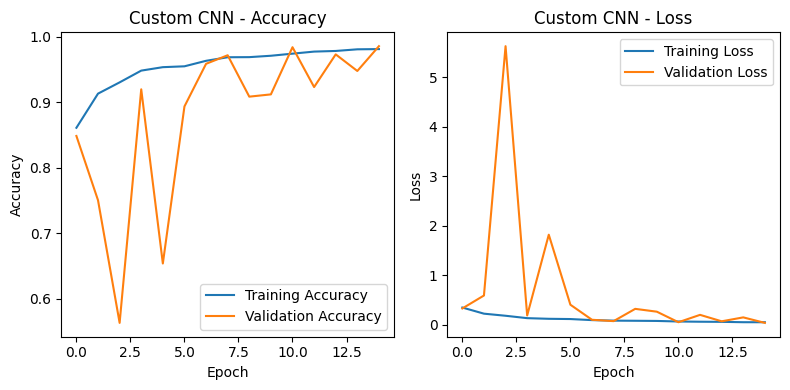

In [28]:
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Training Accuracy")
plt.plot(history_cnn.history["val_accuracy"], label="Validation Accuracy")
plt.title("Custom CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Training Loss")
plt.plot(history_cnn.history["val_loss"], label="Validation Loss")
plt.title("Custom CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "custom_cnn_training_graphs.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [25]:
test_loss, test_accuracy = cnn_model.evaluate(test_ds)

print("Custom CNN Test Results")
print("-----------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

118/118 ━━━━━━━━━━━━━━━━━━━━ 9s 79ms/step - accuracy: 0.9851 - loss: 0.0415
Custom CNN Test Results
-----------------------
Test Loss: 0.0415
Test Accuracy: 98.51%


In [26]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob = cnn_model.predict(test_ds)

y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))

118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 89ms/step
              precision    recall  f1-score   support

   colon_aca     0.9894    1.0000    0.9947       750
     colon_n     1.0000    0.9893    0.9946       750
    lung_aca     0.9821    0.9533    0.9675       750
      lung_n     1.0000    1.0000    1.0000       750
    lung_scc     0.9547    0.9827    0.9685       750

    accuracy                         0.9851      3750
   macro avg     0.9853    0.9851    0.9851      3750
weighted avg     0.9853    0.9851    0.9851      3750



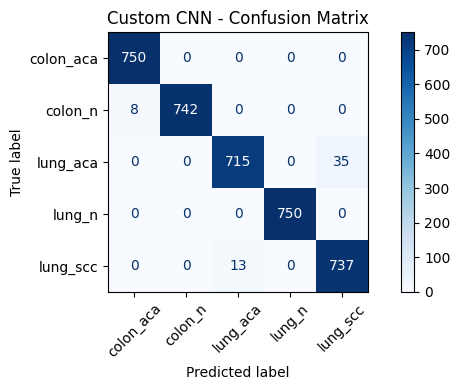

In [29]:
cm = confusion_matrix(y_true, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 4))

display.plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("Custom CNN - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "custom_cnn_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [30]:
from google.colab import files

files.download(
    "/content/Lung_Colon_Cancer_Project/models/custom_cnn_best.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [31]:
import json

with open(
    "/content/Lung_Colon_Cancer_Project/models/class_names.json",
    "w"
) as f:
    json.dump(class_names, f)

files.download(
    "/content/Lung_Colon_Cancer_Project/models/class_names.json"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
!pip -q install -U kaggle

In [4]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from pathlib import Path
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
print("Kaggle authentication successful.")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Kaggle authentication successful.


In [5]:
PROJECT_DIR = Path("/content/Lung_Colon_Cancer_Project")
DATA_DIR = PROJECT_DIR / "dataset"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

for folder in [DATA_DIR, MODEL_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folders created.")

Project folders created.


In [6]:
!kaggle datasets download \
    -d andrewmvd/lung-and-colon-cancer-histopathological-images \
    -p /content/Lung_Colon_Cancer_Project/dataset \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/andrewmvd/lung-and-colon-cancer-histopathological-images
License(s): CC-BY-SA-4.0
100% 1.76G/1.76G [00:47<00:00, 40.0MB/s]



In [7]:
class_names = [
    "colon_aca",
    "colon_n",
    "lung_aca",
    "lung_n",
    "lung_scc"
]

image_extensions = {".jpg", ".jpeg", ".png"}
class_image_paths = {}

for class_name in class_names:
    matches = list(DATA_DIR.rglob(class_name))

    if not matches:
        raise FileNotFoundError(f"Missing folder: {class_name}")

    images = [
        p for p in matches[0].iterdir()
        if p.is_file() and p.suffix.lower() in image_extensions
    ]

    class_image_paths[class_name] = images
    print(class_name, ":", len(images))

print("Total images:", sum(map(len, class_image_paths.values())))

colon_aca : 5000
colon_n : 5000
lung_aca : 5000
lung_n : 5000
lung_scc : 5000
Total images: 25000


In [9]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("/content/Lung_Colon_Cancer_Project/dataset")

class_names = [
    "colon_aca",
    "colon_n",
    "lung_aca",
    "lung_n",
    "lung_scc"
]

image_extensions = {".jpg", ".jpeg", ".png"}

records = []

for class_name in class_names:

    matches = list(DATA_DIR.rglob(class_name))

    if not matches:
        raise FileNotFoundError(f"Folder not found: {class_name}")

    class_folder = matches[0]

    for path in class_folder.iterdir():

        if path.is_file() and path.suffix.lower() in image_extensions:

            records.append({
                "filepath": str(path),
                "label": class_name
            })

dataset_df = pd.DataFrame(records)

print("Dataset shape:", dataset_df.shape)
print("\nClass distribution:")
print(dataset_df["label"].value_counts())

Dataset shape: (25000, 2)

Class distribution:
label
colon_aca    5000
colon_n      5000
lung_aca     5000
lung_n       5000
lung_scc     5000
Name: count, dtype: int64


In [10]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    dataset_df,
    test_size=0.30,
    stratify=dataset_df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

Training: 17500
Validation: 3750
Testing: 3750


In [11]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from tensorflow.keras import layers, models

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

class_to_index = {
    name: index for index, name in enumerate(class_names)
}

PROJECT_DIR = Path("/content/Lung_Colon_Cancer_Project")
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("GPU:", tf.config.list_physical_devices("GPU"))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [12]:
def load_and_preprocess_image(filepath, label):
    image = tf.io.read_file(filepath)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

In [13]:
def create_tf_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels = dataframe["label"].map(class_to_index).values

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(5000, seed=42)

    ds = ds.map(
        load_and_preprocess_image,
        num_parallel_calls=AUTOTUNE
    )

    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = create_tf_dataset(train_df, training=True)
val_ds = create_tf_dataset(val_df)
test_ds = create_tf_dataset(test_df)

print("All datasets created successfully.")

All datasets created successfully.


In [14]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("MobileNetV2 loaded successfully.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
MobileNetV2 loaded successfully.


In [15]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
])

inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)
x = layers.Rescaling(scale=2.0, offset=-1.0)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)

outputs = layers.Dense(5, activation="softmax")(x)

mobilenet_model = models.Model(
    inputs,
    outputs,
    name="MobileNetV2_TransferLearning"
)

mobilenet_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()

Model: "MobileNetV2_TransferLearning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,597 (9.24 MB)

 Trainable params: 164,613 (643.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
mobilenet_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "mobilenetv2_best.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [17]:
history_mobilenet = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=mobilenet_callbacks
)

Epoch 1/5
547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.8810 - loss: 0.3203
Epoch 1: val_loss improved from None to 0.07013, saving model to /content/Lung_Colon_Cancer_Project/models/mobilenetv2_best.keras

Epoch 1: finished saving model to /content/Lung_Colon_Cancer_Project/models/mobilenetv2_best.keras
547/547 ━━━━━━━━━━━━━━━━━━━━ 70s 109ms/step - accuracy: 0.9280 - loss: 0.1951 - val_accuracy: 0.9741 - val_loss: 0.0701
Epoch 2/5
547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.9576 - loss: 0.1098
Epoch 2: val_loss improved from 0.07013 to 0.06010, saving model to /content/Lung_Colon_Cancer_Project/models/mobilenetv2_best.keras

Epoch 2: finished saving model to /content/Lung_Colon_Cancer_Project/models/mobilenetv2_best.keras
547/547 ━━━━━━━━━━━━━━━━━━━━ 74s 103ms/step - accuracy: 0.9589 - loss: 0.1076 - val_accuracy: 0.9773 - val_loss: 0.0601
Epoch 3/5
547/547 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.9638 - loss: 0.0914
Epoch 3: val_loss did not improve from 

In [18]:
test_loss_m, test_accuracy_m = mobilenet_model.evaluate(test_ds)

print("MobileNetV2 Test Results")
print("------------------------")
print(f"Test Loss: {test_loss_m:.4f}")
print(f"Test Accuracy: {test_accuracy_m * 100:.2f}%")

118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 103ms/step - accuracy: 0.9816 - loss: 0.0490
MobileNetV2 Test Results
------------------------
Test Loss: 0.0490
Test Accuracy: 98.16%


In [19]:
from sklearn.metrics import classification_report, confusion_matrix

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_prob_m = mobilenet_model.predict(test_ds)

y_pred_m = np.argmax(y_prob_m, axis=1)

print(classification_report(
    y_true,
    y_pred_m,
    target_names=class_names,
    digits=4
))

118/118 ━━━━━━━━━━━━━━━━━━━━ 12s 94ms/step
              precision    recall  f1-score   support

   colon_aca     0.9960    0.9960    0.9960       750
     colon_n     0.9973    0.9960    0.9967       750
    lung_aca     0.9804    0.9320    0.9556       750
      lung_n     1.0000    1.0000    1.0000       750
    lung_scc     0.9365    0.9840    0.9597       750

    accuracy                         0.9816      3750
   macro avg     0.9820    0.9816    0.9816      3750
weighted avg     0.9820    0.9816    0.9816      3750



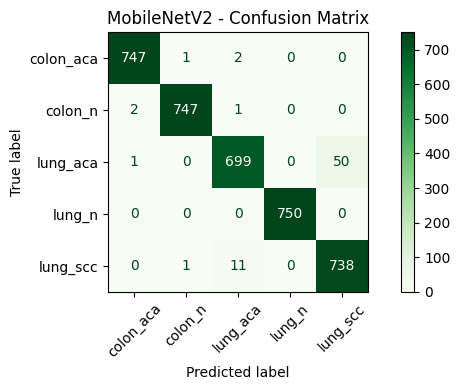

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

cm_m = confusion_matrix(y_true, y_pred_m)

fig, ax = plt.subplots(figsize=(7, 4))

ConfusionMatrixDisplay(
    confusion_matrix=cm_m,
    display_labels=class_names
).plot(
    cmap="Greens",
    xticks_rotation=45,
    ax=ax
)

plt.title("MobileNetV2 - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "mobilenetv2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
comparison_df = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Test Accuracy (%)": [
        98.51,
        test_accuracy_m * 100
    ],
    "Test Loss": [
        np.nan,
        test_loss_m
    ]
})

display(comparison_df)

comparison_df.to_csv(
    RESULTS_DIR / "model_comparison.csv",
    index=False
)

,Model,Test Accuracy (%),Test Loss
0,Custom CNN,98.510000,NaN
1,MobileNetV2,98.159999,0.049043


In [23]:
import shutil

shutil.make_archive(
    "/content/Lung_Colon_Cancer_models",
    "zip",
    root_dir=MODEL_DIR
)

print("Model archive created.")

Model archive created.


In [24]:
from google.colab import files

files.download("/content/Lung_Colon_Cancer_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
from sklearn.metrics import classification_report
import pandas as pd
import json

# Save classification report
report = classification_report(
    y_true,
    y_pred_m,
    target_names=class_names,
    output_dict=True
)

report_df = pd.DataFrame(report).transpose()

report_df.to_csv(
    RESULTS_DIR / "mobilenetv2_classification_report.csv"
)

# Save class names
with open(RESULTS_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f, indent=4)

print("Evaluation results saved successfully!")

Evaluation results saved successfully!


In [26]:
plt.savefig(
    RESULTS_DIR / "mobilenetv2_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>